In [1]:
import tensorflow as tf 
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D,MaxPooling2D,Flatten,Dense,Rescaling
import matplotlib.pyplot as plt
import numpy as np

In [11]:

train_dir = r'C:\Users\Admin\Downloads\xray\chest_xray\train'
test_dir = r'C:\Users\Admin\Downloads\xray\chest_xray\test'

In [12]:
img_height,img_width =150 ,150
batch_size=32

In [13]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(img_height,img_width),
    batch_size=batch_size,
    color_mode='grayscale',
    label_mode='binary'
)

Found 5216 files belonging to 2 classes.


In [14]:
test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    color_mode='grayscale',
    label_mode='binary'
)

Found 624 files belonging to 2 classes.


In [15]:
class_names = train_dataset.class_names
print(f"Detected Classes: {class_names}")

Detected Classes: ['NORMAL', 'PNEUMONIA']


In [18]:
model=Sequential([
    Rescaling(1./255,input_shape=(img_height,img_width,1)),
    Conv2D(32,(3,3),activation='relu'),
    MaxPooling2D(pool_size=(2,2)),
    Conv2D(64,(3,3),activation='relu'),
    MaxPooling2D(pool_size=(2,2)),
    Flatten(),
    Dense(64,activation='relu'),
    Dense(1,activation='sigmoid')
])

d:\Anaconda\Lib\site-packages\keras\src\layers\preprocessing\data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [19]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [20]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 150, 150, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 82944)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     5,308,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,327,361 (20.32 MB)

 Trainable params: 5,327,361 (20.32 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
history=model.fit(train_dataset,epochs=3,validation_data=test_dataset)

Epoch 1/3


d:\Anaconda\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


163/163 ━━━━━━━━━━━━━━━━━━━━ 152s 884ms/step - accuracy: 0.9212 - loss: 0.2033 - val_accuracy: 0.7468 - val_loss: 0.8875
Epoch 2/3
163/163 ━━━━━━━━━━━━━━━━━━━━ 114s 695ms/step - accuracy: 0.9689 - loss: 0.0830 - val_accuracy: 0.7484 - val_loss: 1.1711
Epoch 3/3
163/163 ━━━━━━━━━━━━━━━━━━━━ 145s 712ms/step - accuracy: 0.9755 - loss: 0.0723 - val_accuracy: 0.7740 - val_loss: 0.9894


In [24]:
test_loss,test_accuracy = model.evaluate(test_dataset)
print(f"\nFinal test accuracy:{test_accuracy*100:.2f}%")

20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 221ms/step - accuracy: 0.7740 - loss: 0.9894

Final test accuracy:77.40%


In [26]:
plt.figure(figsize=(12,4))

<Figure size 1200x400 with 0 Axes>

<Figure size 1200x400 with 0 Axes>

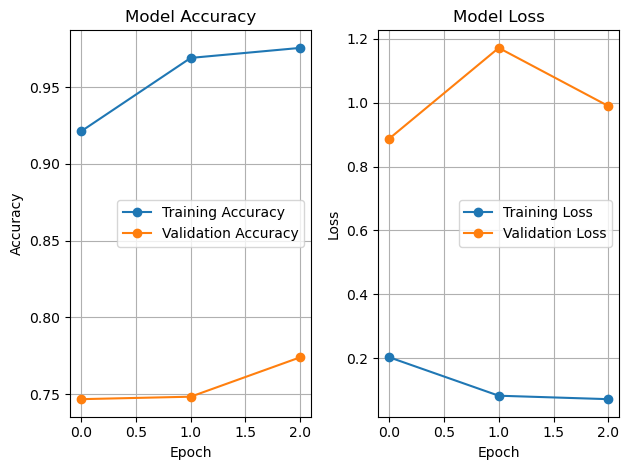

In [27]:
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy', marker='o')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', marker='o')
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.grid(True)

# Loss Plot
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss', marker='o')
plt.plot(history.history['val_loss'], label='Validation Loss', marker='o')
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [29]:
for images,labels in test_dataset.take(1):
    img = images[0]
    actual_label = int(labels[0].numpy())
    break
prediction_prob = model.predict(tf.expand_dims(img,axis=0))
predicted_label = 0 if prediction_prob[0][0] > 0.5 else 0
print(f"Predicted Probability: {prediction_prob[0][0]:.4f}")
print(f"Predicted Class: {class_names[predicted_label]}")
print(f"Actual Class: {class_names[actual_label]}")

C:\Users\Admin\AppData\Local\Temp\ipykernel_6088\560548780.py:3: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  actual_label = int(labels[0].numpy())


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 223ms/step
Predicted Probability: 0.9999
Predicted Class: NORMAL
Actual Class: PNEUMONIA


In [31]:
plt.figure(figsize=(4,4))

<Figure size 400x400 with 0 Axes>

<Figure size 400x400 with 0 Axes>

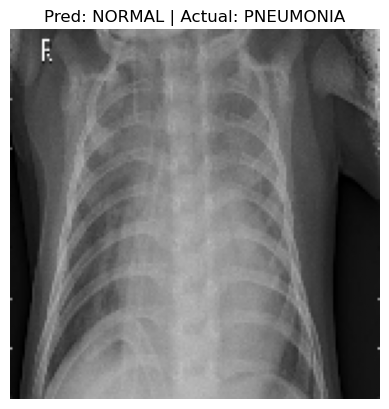

In [33]:
plt.imshow(img.numpy().squeeze(),cmap='gray')
plt.title(f"Pred: {class_names[predicted_label]} | Actual: {class_names[actual_label]}")
plt.axis('off')
plt.show()